# Saudi Employee Attrition Survey

This notebook evaluates individual and voting classifiers with ReliefF and MultiSURF on the Saudi employee attrition survey. The target records whether a respondent has previously left an employer, so the analysis is retrospective. The notebook includes preprocessing, fold-local feature selection and SMOTE, feature-count optimisation, holdout evaluation, three-seed stability analysis, and SHAP interpretation.

**Evaluation protocol**
- Seed 42 is used for the stratified 80/20 split and the main five-fold cross-validation.
- Target encoding, scaling, feature ranking, and SMOTE are fitted using training-fold data only.
- The feature count is selected by mean cross-validation F1.
- The untouched holdout set is used for the final descriptive comparison.
- Seeds 42, 43, and 44 assess the stability of the selected voting configuration.

This copy retains the original preprocessing, classifiers, parameter grids,
and fold-specific ranking. Training CV selects the final configuration.
An all-features baseline uses the original input column order. Selector
runs retain their original ranking order, including at the full count.
Stochastic models can therefore produce different predictions even when
the feature set is identical. Full-count rows represent the same predictors,
and do not demonstrate feature reduction.

The existing holdout was examined during earlier analyses. Results on it
are internal descriptive comparisons. Bootstrap intervals condition on
the fitted model and this split. The fixed-configuration seed analysis
covers voting classifiers and does not assess the complete selection
procedure. Saudi labels concern previous attrition.


## Import Libraries


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import zscore
from sklearn.preprocessing import MinMaxScaler, LabelEncoder, OrdinalEncoder
import warnings
warnings.filterwarnings('ignore')

sns.set(style="whitegrid", palette="Set2", font_scale=1.2)


## Load Dataset & Overview


In [2]:
# Load Dataset
file_path = "Original Dataset of Employee Attrition.xlsx"
df = pd.read_excel(file_path)

# Normalize column names (trim spaces, replace & with _, replace spaces with _)
df.columns = (
    df.columns
      .str.strip()
      .str.replace(r"\s+", " ", regex=True)
      .str.replace("&", "_", regex=False)
      .str.replace(" ", "", regex=False)
      .str.replace(r"_+", "_", regex=True)
      .str.strip("_")
)

print("="*60)
print("DATASET OVERVIEW")
print("="*60)
print(f"Total Rows: {df.shape[0]}")
print(f"Total Columns: {df.shape[1]}")
print(f"\nColumn Names:\n{df.columns.tolist()}")

print("\n" + "="*60)
print("DATA TYPES")
print("="*60)
df.info()

df.head()


DATASET OVERVIEW
Total Rows: 1191
Total Columns: 35

Column Names:
['ID', 'Attrition', 'Gender', 'Age', 'Maritalstatus', 'Academic_degree', 'Years_Experience', 'Years_experience_lastorganization', 'Sector', 'Department', 'JobTitle', 'MonthlySalary', 'Allowances', 'MedicalInsurance', 'Bonus', 'OverTime', 'Payment_Overtime', 'Rewards_Wages_Satisfaction', 'Get_Deserved_Promotion', 'Training_programs_During_last_three_years', 'Useful_Training_Programs', 'Business_Travel', 'Job_Support', 'Recognition', 'Emotional_Commitment', 'Job_Engagement', 'Distance_to_work', 'Work_Live_Balance', 'Physical_Stress', 'Psychological_Exhaustion', 'Job_Stability', 'Health_Issues', 'Environment_Satisfaction', 'Job_Satisfaction', 'Job_Opportunities']

DATA TYPES
<class 'pandas.DataFrame'>
RangeIndex: 1191 entries, 0 to 1190
Data columns (total 35 columns):
 #   Column                                     Non-Null Count  Dtype
---  ------                                     --------------  -----
 0   ID         

,ID,Attrition,Gender,Age,Maritalstatus,Academic_degree,Years_Experience,Years_experience_lastorganization,Sector,Department,...,Job_Engagement,Distance_to_work,Work_Live_Balance,Physical_Stress,Psychological_Exhaustion,Job_Stability,Health_Issues,Environment_Satisfaction,Job_Satisfaction,Job_Opportunities
0,11,Yes,Female,31 to 40,Married,Master's,Less than 5 years,Less than 5 years,Medical sector,Accounting,...,Medium,Medium,Medium,Yes,No,No,Yes,Medium,Not satisfied,Yes
1,12,No,Female,21 to 30,Single,Master's,Less than 5 years,Less than 5 years,Medical sector,Accounting,...,Medium,Medium,Medium,No,No,Yes,No,Medium,Satisfied,No
2,13,No,Female,21 to 30,Single,Bachelor's,Less than 5 years,Less than 5 years,Education sector,Teaching,...,Medium,Close,Medium,Yes,Sometimes,No,No,Medium,Satisfied,Yes
3,14,No,Female,21 to 30,Single,Bachelor's,Less than 5 years,Less than 5 years,Education sector,Teaching,...,Medium,Medium,Medium,Yes,Yes,No,No,Low,Not satisfied,No
4,15,No,Female,21 to 30,Single,Bachelor's,Less than 5 years,Less than 5 years,Education sector,Teaching,...,Medium,Medium,Medium,Sometimes,Sometimes,No,No,Medium,Not satisfied,No


## Missing Values Analysis & Imputation


In [3]:
print("="*60)
print("MISSING VALUES ANALYSIS")
print("="*60)

missing = df.isna().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({"Missing Count": missing, "Percentage": missing_pct})
missing_before = int(missing.sum())
if missing_before:
    print(missing_df[missing_df["Missing Count"] > 0].sort_values("Missing Count", ascending=False))
    print("Imputation is deferred until after the train-test split and fitted on training data only.")
else:
    print("No missing values detected. The train-only imputation code remains as a safeguard.")


MISSING VALUES ANALYSIS
No missing values detected. The train-only imputation code remains as a safeguard.


---
# PREPROCESSING PIPELINE
---


## Irrelevant Feature Removal


In [4]:
print("="*60)
print("IRRELEVANT FEATURE REMOVAL")
print("="*60)
print("Identifying constant/administrative features that don't contribute to prediction...")

# Store original shape
original_shape = df.shape
features_to_remove = []

# Check for constant features (same value across all records)
for col in df.columns:
    if df[col].nunique() == 1:
        features_to_remove.append(col)
        print(f"  - '{col}': Constant value ({df[col].iloc[0]}) - REMOVED")

# Check for ID-like features (unique per record, no predictive value)
for col in df.columns:
    if col not in features_to_remove:
        # If column has as many unique values as rows, it's likely an ID
        if df[col].nunique() == len(df) and df[col].dtype in ['int64', 'float64', 'object']:
            if 'id' in col.lower() or 'number' in col.lower() or 'employee' in col.lower():
                features_to_remove.append(col)
                print(f"  - '{col}': Identifier column (unique per record) - REMOVED")

# Common administrative features to check
admin_features = ['EmployeeCount', 'Over18', 'StandardHours', 'EmployeeNumber', 'EmployeeID']
for feat in admin_features:
    if feat in df.columns and feat not in features_to_remove:
        if df[feat].nunique() <= 2:  # Constant or near-constant
            features_to_remove.append(feat)
            print(f"  - '{feat}': Administrative feature - REMOVED")

# Remove identified features
if features_to_remove:
    df = df.drop(columns=features_to_remove, errors='ignore')
    print(f"\n✓ Removed {len(features_to_remove)} irrelevant feature(s)")
    print(f"  Shape before: {original_shape} → Shape after: {df.shape}")
else:
    print("✓ No constant or administrative features detected.")


IRRELEVANT FEATURE REMOVAL
Identifying constant/administrative features that don't contribute to prediction...
  - 'ID': Identifier column (unique per record) - REMOVED

✓ Removed 1 irrelevant feature(s)
  Shape before: (1191, 35) → Shape after: (1191, 34)


## Categorical Label Standardisation


In [5]:
print("="*60)
print("CATEGORICAL LABEL STANDARDISATION")
print("="*60)
print("Normalising whitespace and letter case with deterministic rules...")

categorical_cols = df.select_dtypes(include=["object", "string", "str"]).columns
for col in categorical_cols:
    df[col] = (
        df[col].astype("string").str.strip().str.replace(r"\s+", " ", regex=True).str.casefold()
    )
print(f"Standardised {len(categorical_cols)} text columns using strip, whitespace collapse, and casefold.")


CATEGORICAL LABEL STANDARDISATION
Normalising whitespace and letter case with deterministic rules...
Standardised 33 text columns using strip, whitespace collapse, and casefold.


## Rare Category Grouping


In [6]:
print("="*60)
print("RARE CATEGORY GROUPING")
print("="*60)
print("Rare nominal categories are grouped after the split using training frequencies only.")


RARE CATEGORY GROUPING
Rare nominal categories are grouped after the split using training frequencies only.


## Outlier Detection (No Rows Removed) (Z-Score)


In [7]:
print("="*60)
print("OUTLIER DETECTION (Z-SCORE METHOD)")
print("="*60)
print("Identifying anomalous data points with |Z-score| > 3...")

# Get numeric columns (excluding target variable)
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
if 'Attrition' in numeric_cols:
    numeric_cols.remove('Attrition')

original_len = len(df)
outlier_details = {}

# Calculate Z-scores for each numeric column
z_scores = df[numeric_cols].apply(zscore, nan_policy='omit')

# Identify rows with any Z-score > 3
outlier_mask = (z_scores.abs() > 3).any(axis=1)
outliers_per_column = (z_scores.abs() > 3).sum()

print("\nOutliers detected per feature (|Z| > 3):")
for col in numeric_cols:
    count = outliers_per_column[col]
    if count > 0:
        print(f"  - {col}: {count} outliers")
        outlier_details[col] = count

total_outlier_rows = outlier_mask.sum()
print(f"\nTotal rows with at least one outlier: {total_outlier_rows} ({total_outlier_rows/len(df)*100:.2f}%)")

print("\n✓ Outlier detection complete.")


OUTLIER DETECTION (Z-SCORE METHOD)
Identifying anomalous data points with |Z-score| > 3...

Outliers detected per feature (|Z| > 3):

Total rows with at least one outlier: 0 (0.00%)

✓ Outlier detection complete.


## Target Variable Encoding


In [8]:
print("="*60)
print("TARGET VARIABLE ENCODING")
print("="*60)

# Convert both object and pandas StringDtype targets to numeric 0/1.
target = df['Attrition']
if not pd.api.types.is_numeric_dtype(target):
    print("Converting target variable 'Attrition' from labels to binary...")
    normalized_target = target.astype('string').str.strip().str.lower()
    encoded_target = normalized_target.map({'yes': 1, 'no': 0, '1': 1, '0': 0})
    if encoded_target.isna().any():
        unknown_values = sorted(normalized_target[encoded_target.isna()].dropna().unique().tolist())
        raise ValueError(f"Unexpected Attrition labels: {unknown_values}")
    df['Attrition'] = encoded_target.astype('int64')
else:
    df['Attrition'] = pd.to_numeric(target, errors='raise').astype('int64')
print("✓ Target encoding complete.")
print(f"  - dtype: {df['Attrition'].dtype}")
print(f"  - Value distribution: {df['Attrition'].value_counts().sort_index().to_dict()}")


TARGET VARIABLE ENCODING
Converting target variable 'Attrition' from labels to binary...
✓ Target encoding complete.
  - dtype: int64
  - Value distribution: {0: 676, 1: 515}


## Train-Test Split

In [9]:
# Train-Test Split
import random
import numpy as np
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("="*60)
print("TRAIN-TEST SPLIT")
print("="*60)

X = df.drop("Attrition", axis=1)
y = df["Attrition"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

print(f"\nTrain shape: {X_train.shape}")
print(f"Test shape: {X_test.shape}")
print("\nTrain target distribution:")
print(f"  - 0 (No): {(y_train==0).sum()}")
print(f"  - 1 (Yes): {(y_train==1).sum()}")
print("\nTest target distribution:")
print(f"  - 0 (No): {(y_test==0).sum()}")
print(f"  - 1 (Yes): {(y_test==1).sum()}")


# Fit imputation values on the training partition only.
numeric_columns_train = X_train.select_dtypes(include=["number"]).columns
categorical_columns_train = X_train.select_dtypes(include=["object", "string", "str"]).columns
train_medians = X_train[numeric_columns_train].median()
X_train.loc[:, numeric_columns_train] = X_train[numeric_columns_train].fillna(train_medians)
X_test.loc[:, numeric_columns_train] = X_test[numeric_columns_train].fillna(train_medians)
for col in categorical_columns_train:
    mode = X_train[col].mode(dropna=True)
    fill_value = mode.iloc[0] if not mode.empty else "unknown"
    X_train[col] = X_train[col].fillna(fill_value)
    X_test[col] = X_test[col].fillna(fill_value)

# Group rare nominal categories from training frequencies only. Ordered salary
# and experience ranges are retained explicitly rather than collapsed as "other".
rare_threshold = 0.01
minimum_category_count = max(1, int(np.ceil(len(X_train) * rare_threshold)))
rare_group_columns = ["JobTitle", "Sector", "Department", "Maritalstatus"]
rare_category_maps = {}
for col in rare_group_columns:
    if col not in X_train.columns:
        continue
    counts = X_train[col].value_counts(dropna=False)
    rare_values = set(counts[counts < minimum_category_count].index)
    retained_values = set(counts.index) - rare_values
    rare_category_maps[col] = rare_values
    X_train[col] = X_train[col].where(~X_train[col].isin(rare_values), "other")
    X_test[col] = X_test[col].where(X_test[col].isin(retained_values), "other")
    print(f"{col}: grouped {len(rare_values)} training-rare categories; unseen test categories map to 'other'.")


TRAIN-TEST SPLIT

Train shape: (952, 33)
Test shape: (239, 33)

Train target distribution:
  - 0 (No): 540
  - 1 (Yes): 412

Test target distribution:
  - 0 (No): 136
  - 1 (Yes): 103
JobTitle: grouped 35 training-rare categories; unseen test categories map to 'other'.
Sector: grouped 2 training-rare categories; unseen test categories map to 'other'.
Department: grouped 5 training-rare categories; unseen test categories map to 'other'.
Maritalstatus: grouped 0 training-rare categories; unseen test categories map to 'other'.


## Categorical Variable Encoding (Train & Test)


In [10]:
print("="*60)
print("CATEGORICAL VARIABLE ENCODING (TRAIN SET)")
print("="*60)
print("Fitting encoders on train set, transforming both train and test...")

# ============================================================================
# DEFINE ENCODING CATEGORIES
# ============================================================================

binary_columns = [
    'Job_Opportunities', 'Job_Stability', 'Health_Issues', 'Recognition',
    'Useful_Training_Programs', 'Get_Deserved_Promotion', 'Rewards_Wages_Satisfaction',
    'OverTime', 'Bonus', 'MedicalInsurance', 'Gender',
]

# Nominal columns (target-encoded inside each model fit)
nominal_columns = ['JobTitle', 'Sector', 'Department', 'Maritalstatus']

# Ordinal variables (ordinal-coded before plain SMOTE)
ordinal_columns = [
    'Job_Satisfaction', 'Environment_Satisfaction', 'Emotional_Commitment', 'Job_Support',
    'Psychological_Exhaustion', 'Physical_Stress', 'Work_Live_Balance', 'Job_Engagement',
    'Distance_to_work', 'Business_Travel', 'Training_programs_During_last_three_years',
    'Payment_Overtime', 'MonthlySalary', 'Years_experience_lastorganization',
    'Years_Experience', 'Academic_degree', 'Age',
]

binary_cols = [col for col in binary_columns if col in X_train.columns]
nominal_cols = [col for col in nominal_columns if col in X_train.columns]
ordinal_cols = [col for col in ordinal_columns if col in X_train.columns]

print(f"\nColumn Classification:")
print(f"  - Binary columns ({len(binary_cols)}): {binary_cols}")
print(f"  - Ordinal columns ({len(ordinal_cols)}): {ordinal_cols}")
print(f"  - Nominal columns ({len(nominal_cols)}): {nominal_cols}")

# ============================================================================
# 1. LABEL ENCODING for Binary columns (Yes/No)
# ============================================================================
print(f"\n--- Label Encoding (Binary Columns) ---")
binary_encoders = {}
for col in binary_cols:
    if col in X_train.columns:
        le = LabelEncoder()
        X_train[col] = le.fit_transform(X_train[col].astype(str))
        X_test[col] = le.transform(X_test[col].astype(str))
        binary_encoders[col] = le
        print(f"  {col}: Fitted on train, transformed both")

# ============================================================================
# 2. ORDINAL ENCODING for ordinal columns (sklearn)
# ============================================================================
print(f"\n--- Ordinal Encoding (Fitted on Train Set) ---")

ordinal_categories = {
    'Job_Satisfaction': ['not satisfied', 'satisfied', 'very satisfied'],
    'Academic_degree': ['diploma or secondary', "bachelor's", "master's", 'ph.d'],
    'Environment_Satisfaction': ['low', 'medium', 'high'],
    'Emotional_Commitment': ['low', 'medium', 'high'],
    'Job_Support': ['low', 'medium', 'high'],
    'Psychological_Exhaustion': ['no', 'sometimes', 'yes'],
    'Physical_Stress': ['no', 'sometimes', 'yes'],
    'Work_Live_Balance': ['easy', 'medium', 'difficult'],
    'Job_Engagement': ['easy', 'medium', 'difficult'],
    'Distance_to_work': ['close', 'medium', 'far'],
    'Business_Travel': ['i do not travel for work', 'travel rarely', 'travel frequently'],
    'Payment_Overtime': ["i don't have overtime", 'no', 'yes'],
    'MonthlySalary': ['less than 5000 sar', 'from 5000 to 10000 s.r', 'from 11000 to 15000 s.r', 'from 16000 to 20000 s.r', 'from 21000 to 25000 s.r', 'from 26000 to 30000 s.r', 's.r 31000 - and more'],
    'Years_experience_lastorganization': ['less than 5 years', 'from 5 to 10 years', 'from 11 to 15 years', 'from 16 to 20 years', 'from 21 to 25 years', 'from 26 to 30 years', 'from 31 to 35 years'],
    'Years_Experience': ['less than 5 years', 'from 5 to 10 years', 'from 11 to 15 years', 'from 16 to 20 years', 'from 21 to 25 years', 'from 26 to 30 years', 'from 31 to 35 years'],
    'Age': ['21 to 30', '31 to 40', '41 to 50', '51 to 60'],
    'Training_programs_During_last_three_years': ['i did not receive any training', 'from 1 to 3 training programs', 'from 4 to 6 training programs', 'from 7 training programs to more'],
}

ordinal_cols_present = [col for col in ordinal_categories.keys() if col in X_train.columns]

if ordinal_cols_present:
    categories_list = [ordinal_categories[col] for col in ordinal_cols_present]
    ordinal_encoder = OrdinalEncoder(
        categories=categories_list,
        handle_unknown='use_encoded_value',
        unknown_value=-1
    )
    X_train[ordinal_cols_present] = ordinal_encoder.fit_transform(X_train[ordinal_cols_present].astype(str))
    X_test[ordinal_cols_present] = ordinal_encoder.transform(X_test[ordinal_cols_present].astype(str))
    X_train[ordinal_cols_present] = X_train[ordinal_cols_present].astype(int)
    X_test[ordinal_cols_present] = X_test[ordinal_cols_present].astype(int)
    print(f"  ✓ OrdinalEncoder fitted on train set, applied to {len(ordinal_cols_present)} columns")

# ============================================================================
# 3. NOMINAL TARGET ENCODING (deferred to each model fit)
# ============================================================================
print(f"\n--- Nominal Target Encoding (Inside Each Model Fit) ---")
if nominal_cols:
    print("  ✓ Nominal labels retained for fold-local target encoding")
else:
    print("  ✓ No nominal columns require target encoding")

print("\n✓ Binary and ordinal encoding complete. Nominal encoding occurs inside each model fit.")


CATEGORICAL VARIABLE ENCODING (TRAIN SET)
Fitting encoders on train set, transforming both train and test...

Column Classification:
  - Binary columns (11): ['Job_Opportunities', 'Job_Stability', 'Health_Issues', 'Recognition', 'Useful_Training_Programs', 'Get_Deserved_Promotion', 'Rewards_Wages_Satisfaction', 'OverTime', 'Bonus', 'MedicalInsurance', 'Gender']
  - Ordinal columns (17): ['Job_Satisfaction', 'Environment_Satisfaction', 'Emotional_Commitment', 'Job_Support', 'Psychological_Exhaustion', 'Physical_Stress', 'Work_Live_Balance', 'Job_Engagement', 'Distance_to_work', 'Business_Travel', 'Training_programs_During_last_three_years', 'Payment_Overtime', 'MonthlySalary', 'Years_experience_lastorganization', 'Years_Experience', 'Academic_degree', 'Age']
  - Nominal columns (4): ['JobTitle', 'Sector', 'Department', 'Maritalstatus']

--- Label Encoding (Binary Columns) ---
  Job_Opportunities: Fitted on train, transformed both
  Job_Stability: Fitted on train, transformed both
  Heal

  ✓ OrdinalEncoder fitted on train set, applied to 17 columns

--- Nominal Target Encoding (Inside Each Model Fit) ---
  ✓ Nominal labels retained for fold-local target encoding

✓ Binary and ordinal encoding complete. Nominal encoding occurs inside each model fit.


## Fold-Safe Preprocessing

In [11]:
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import StandardScaler

print("="*60)
print("TARGET ENCODING AND NUMERIC PREPARATION")
print("="*60)

# Preserve the train-only, mixed-type feature matrix for fold-wise pipelines.
# The model pipelines below fit this target encoder inside each CV fold.
X_train_raw_model = X_train.copy()
X_test_raw_model = X_test.copy()

class MEstimateTargetEncoder(BaseEstimator, TransformerMixin):
    """Fold-safe smoothed target encoding for selected nominal columns."""

    def __init__(self, columns=None, m=10):
        self.columns = columns
        self.m = m

    def fit(self, X, y):
        X_df = X.copy() if isinstance(X, pd.DataFrame) else pd.DataFrame(X)
        self.feature_names_in_ = list(X_df.columns)
        self.global_mean_ = float(np.asarray(y).mean())
        self.maps_ = {}
        columns = self.columns if self.columns is not None else self.feature_names_in_
        for col in columns:
            if col not in X_df.columns:
                continue
            temp = pd.DataFrame({"value": X_df[col], "target": np.asarray(y)})
            stats = temp.groupby("value")["target"].agg(["mean", "count"])
            stats["estimate"] = (
                stats["count"] * stats["mean"] + self.m * self.global_mean_
            ) / (stats["count"] + self.m)
            self.maps_[col] = stats["estimate"].to_dict()
        return self

    def transform(self, X):
        X_df = X.copy() if isinstance(X, pd.DataFrame) else pd.DataFrame(
            X, columns=self.feature_names_in_
        )
        X_df = X_df.copy()
        for col, mapping in self.maps_.items():
            if col in X_df.columns:
                X_df[col] = X_df[col].map(mapping).fillna(self.global_mean_)
        return X_df

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features if input_features is not None else self.feature_names_in_, dtype=object)


class NonBinaryStandardScaler(BaseEstimator, TransformerMixin):
    """Standardize all available features except designated binary indicators."""

    def __init__(self, binary_columns=None):
        self.binary_columns = binary_columns

    def fit(self, X, y=None):
        X_df = X.copy() if isinstance(X, pd.DataFrame) else pd.DataFrame(X)
        X_df = X_df.astype(float)
        self.feature_names_in_ = list(X_df.columns)
        binary = set(self.binary_columns or [])
        self.scale_columns_ = [
            column for column in self.feature_names_in_ if column not in binary
        ]
        self.scaler_ = StandardScaler()
        if self.scale_columns_:
            self.scaler_.fit(X_df[self.scale_columns_])
        return self

    def transform(self, X):
        X_df = X.copy() if isinstance(X, pd.DataFrame) else pd.DataFrame(
            X, columns=self.feature_names_in_
        )
        transformed = X_df.astype(float)
        if self.scale_columns_:
            transformed.loc[:, self.scale_columns_] = self.scaler_.transform(
                transformed[self.scale_columns_]
            )
        return transformed

    def get_feature_names_out(self, input_features=None):
        return np.asarray(
            input_features if input_features is not None else self.feature_names_in_,
            dtype=object,
        )


def m_estimator_target_encode_fit(X_train_local, y_train_local, col, m=10):
    encoder = MEstimateTargetEncoder(columns=[col], m=m)
    encoder.fit(X_train_local[[col]], y_train_local)
    return encoder.maps_.get(col, {}), encoder.global_mean_


def m_estimator_target_encode_transform(X_local, col, encoding_map, global_mean):
    return X_local[col].map(encoding_map).fillna(global_mean)


nominal_encoders = {}
m_value = 10
print(f"\nApplying M-Estimator Target Encoding (m={m_value}) on the full training partition for export...")
print(f"Global target mean (train): {y_train.mean():.4f}\n")

for col in nominal_cols:
    encoding_map, global_mean = m_estimator_target_encode_fit(X_train, y_train, col, m=m_value)
    nominal_encoders[col] = (encoding_map, global_mean)
    X_train[col] = m_estimator_target_encode_transform(X_train, col, encoding_map, global_mean)
    X_test[col] = m_estimator_target_encode_transform(X_test, col, encoding_map, global_mean)
    print(f"  {col}: {len(encoding_map)} categories encoded")

print("\n✓ Export/feature-ranking matrix prepared from the training partition")

from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

print("\n" + "="*60)
print("NON-BINARY STANDARD SCALING AND SMOTE")
print("="*60)

# Binary indicators remain 0/1. Every non-binary feature is standardized.
# Ordinary SMOTE is then applied to the numeric training representation.
non_binary_columns = [
    column for column in X_train.columns if column not in binary_cols
]
X_train = X_train.astype(float)
X_test = X_test.astype(float)
scaler = StandardScaler()
X_train.loc[:, non_binary_columns] = scaler.fit_transform(
    X_train[non_binary_columns]
)
X_test.loc[:, non_binary_columns] = scaler.transform(
    X_test[non_binary_columns]
)

smote = SMOTE(random_state=SEED)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("✓ StandardScaler fitted on non-binary training features only")
print("✓ Plain SMOTE applied only to the training partition")
print(f"  Original train shape: {X_train.shape}")
print(f"  SMOTE train shape: {X_train_smote.shape}")
print(f"  Class distribution after SMOTE: {np.bincount(y_train_smote)}")


TARGET ENCODING AND NUMERIC PREPARATION

Applying M-Estimator Target Encoding (m=10) on the full training partition for export...
Global target mean (train): 0.4328

  JobTitle: 26 categories encoded
  Sector: 14 categories encoded
  Department: 16 categories encoded
  Maritalstatus: 3 categories encoded

✓ Export/feature-ranking matrix prepared from the training partition

NON-BINARY STANDARD SCALING AND SMOTE
✓ StandardScaler fitted on non-binary training features only
✓ Plain SMOTE applied only to the training partition
  Original train shape: (952, 33)
  SMOTE train shape: (1080, 33)
  Class distribution after SMOTE: [540 540]


Test Set Class Distribution:
Class 0: 136 (56.90%)
Class 1: 103 (43.10%)


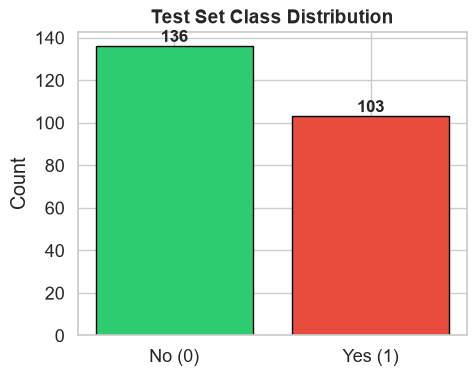

In [12]:
# Display class distribution for the test set
test_counts = y_test.value_counts()
print("Test Set Class Distribution:")
for label, count in test_counts.items():
    print(f"Class {label}: {count} ({count/len(y_test)*100:.2f}%)")

import matplotlib.pyplot as plt
plt.figure(figsize=(5,4))
colors = ['#2ecc71', '#e74c3c']
plt.bar(['No (0)', 'Yes (1)'], [test_counts.get(0,0), test_counts.get(1,0)], color=colors, edgecolor='black')
plt.title('Test Set Class Distribution', fontsize=14, fontweight='bold')
plt.ylabel('Count')
for i, count in enumerate([test_counts.get(0,0), test_counts.get(1,0)]):
    plt.text(i, count + 2, f'{count}', ha='center', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


## Preprocessing Summary


In [13]:
print("="*80)
print("PREPROCESSING SUMMARY")
print("="*80)
print(f"Constant/administrative features removed: {len(features_to_remove)}")
print("Text labels: whitespace-normalised and casefolded deterministically")
print("Missing-value safeguards: fitted on the training partition only")
print(f"Rare nominal threshold: <{rare_threshold*100:.0f}% of training records")
print(f"Outlier rows detected for description only: {total_outlier_rows}; no rows removed")
print(f"Binary columns: {len(binary_cols)}")
print(f"Ordinal columns: {len(ordinal_cols_present)}")
print(f"Target-encoded nominal columns: {len(nominal_cols)}")
print("Non-binary features are standardised; SMOTE is applied to training data only.")
print("="*80)


PREPROCESSING SUMMARY
Constant/administrative features removed: 1
Text labels: whitespace-normalised and casefolded deterministically
Missing-value safeguards: fitted on the training partition only
Rare nominal threshold: <1% of training records
Outlier rows detected for description only: 0; no rows removed
Binary columns: 11
Ordinal columns: 17
Target-encoded nominal columns: 4
Non-binary features are standardised; SMOTE is applied to training data only.


In [14]:
print("Model-ready training matrix before oversampling:")
print(f"Shape: {X_train.shape}")
display(X_train.head())


Model-ready training matrix before oversampling:
Shape: (952, 33)


,Gender,Age,Maritalstatus,Academic_degree,Years_Experience,Years_experience_lastorganization,Sector,Department,JobTitle,MonthlySalary,...,Job_Engagement,Distance_to_work,Work_Live_Balance,Physical_Stress,Psychological_Exhaustion,Job_Stability,Health_Issues,Environment_Satisfaction,Job_Satisfaction,Job_Opportunities
611,1.0,0.505730,-0.853389,0.062623,0.142696,-0.622079,0.558556,1.168860,2.279072,1.140948,...,0.022624,-1.238432,1.602683,1.247327,-0.059301,0.0,1.0,-0.097448,0.076365,1.0
550,1.0,-0.881749,-0.853389,0.062623,0.142696,0.452729,-0.901123,0.689655,0.530290,-0.842947,...,0.022624,0.246439,0.021591,-1.287263,-1.313846,0.0,1.0,-0.097448,0.076365,1.0
1049,0.0,-0.881749,-0.853389,0.062623,-0.834620,-0.622079,-0.473202,0.331485,-0.948577,0.149000,...,0.022624,-1.238432,1.602683,1.247327,1.195244,0.0,1.0,-1.643620,-1.407302,0.0
266,1.0,0.505730,1.131364,-1.466022,0.142696,0.452729,-0.473202,0.766580,0.676076,1.140948,...,1.679404,-1.238432,0.021591,-0.019968,1.195244,0.0,0.0,1.448724,-1.407302,1.0
61,1.0,-0.881749,1.131364,0.062623,-0.834620,-0.622079,0.561693,0.766580,0.530290,0.149000,...,1.679404,0.246439,1.602683,1.247327,1.195244,0.0,0.0,-1.643620,-1.407302,0.0


## Feature Selection

In [15]:
import numpy as np
from skrebate import ReliefF, MultiSURF

print("="*60)
print("FEATURE SELECTION - ReliefF AND MultiSURF")
print("="*60)

# This full-training ranking is used only to fit the final model after the
# feature count has been selected. Fold-local rankings are calculated later
# during cross-validation so that validation labels cannot influence ranking.
feature_names = X_train.columns.tolist()
X_train_np = np.asarray(X_train, dtype=float)
y_train_np = np.asarray(y_train)
ranking_categorical_indices = [
    feature_names.index(column) for column in binary_cols if column in feature_names
]

print(f"\nFeature matrix for final full-training ranking: {X_train.shape}")
print(f"Target distribution: No={sum(y_train==0)}, Yes={sum(y_train==1)}")
print("Only binary indicators are categorical in ReliefF/MultiSURF; encoded ordinal features retain their order.")

print("ReliefF Feature Ranking")
print("-"*60)
relieff = ReliefF(
    n_features_to_select=X_train_np.shape[1], n_neighbors=100,
    categorical_features=ranking_categorical_indices, n_jobs=-1,
)
relieff.fit(X_train_np, y_train_np)
relieff_scores_dict = dict(zip(feature_names, relieff.feature_importances_))
relieff_sorted = sorted(relieff_scores_dict.items(), key=lambda x: x[1], reverse=True)
for i, (feat, score) in enumerate(relieff_sorted, 1):
    print(f"  {i:2d}. {feat}: {score:.4f}")


FEATURE SELECTION - ReliefF AND MultiSURF

Feature matrix for final full-training ranking: (952, 33)
Target distribution: No=540, Yes=412
Only binary indicators are categorical in ReliefF/MultiSURF; encoded ordinal features retain their order.
ReliefF Feature Ranking
------------------------------------------------------------
   1. Job_Opportunities: 0.1617
   2. JobTitle: 0.0771
   3. Sector: 0.0728
   4. Emotional_Commitment: 0.0630
   5. Job_Stability: 0.0530
   6. Rewards_Wages_Satisfaction: 0.0449
   7. Department: 0.0431
   8. Get_Deserved_Promotion: 0.0408
   9. Allowances: 0.0406
  10. Job_Support: 0.0387
  11. Psychological_Exhaustion: 0.0368
  12. Payment_Overtime: 0.0297
  13. OverTime: 0.0296
  14. MedicalInsurance: 0.0263
  15. Training_programs_During_last_three_years: 0.0243
  16. Job_Engagement: 0.0222
  17. Gender: 0.0210
  18. Job_Satisfaction: 0.0209
  19. Health_Issues: 0.0205
  20. Physical_Stress: 0.0194
  21. Work_Live_Balance: 0.0192
  22. Recognition: 0.0192
 

In [16]:
print("MultiSURF Feature Ranking")
print("-"*60)

multisurf = MultiSURF(n_features_to_select=X_train_np.shape[1], categorical_features=ranking_categorical_indices, n_jobs=-1)
multisurf.fit(X_train_np, y_train_np)
multisurf_scores_dict = dict(zip(feature_names, multisurf.feature_importances_))
multisurf_sorted = sorted(multisurf_scores_dict.items(), key=lambda x: x[1], reverse=True)

print("\nAll Features Ranked by MultiSURF Score:")
for i, (feat, score) in enumerate(multisurf_sorted, 1):
    print(f"  {i:2d}. {feat}: {score:.4f}")


MultiSURF Feature Ranking
------------------------------------------------------------

All Features Ranked by MultiSURF Score:
   1. Job_Opportunities: 0.1397
   2. JobTitle: 0.0707
   3. Sector: 0.0609
   4. Emotional_Commitment: 0.0465
   5. Department: 0.0343
   6. Job_Stability: 0.0253
   7. Psychological_Exhaustion: 0.0211
   8. Job_Support: 0.0166
   9. Allowances: 0.0157
  10. Job_Engagement: 0.0152
  11. Rewards_Wages_Satisfaction: 0.0151
  12. Get_Deserved_Promotion: 0.0111
  13. Training_programs_During_last_three_years: 0.0101
  14. Work_Live_Balance: 0.0100
  15. Distance_to_work: 0.0091
  16. Health_Issues: 0.0078
  17. Physical_Stress: 0.0062
  18. Job_Satisfaction: 0.0057
  19. Years_Experience: 0.0048
  20. Years_experience_lastorganization: 0.0047
  21. MonthlySalary: 0.0015
  22. Business_Travel: 0.0005
  23. MedicalInsurance: -0.0008
  24. Academic_degree: -0.0020
  25. Age: -0.0025
  26. Recognition: -0.0031
  27. Environment_Satisfaction: -0.0056
  28. Useful_Trai

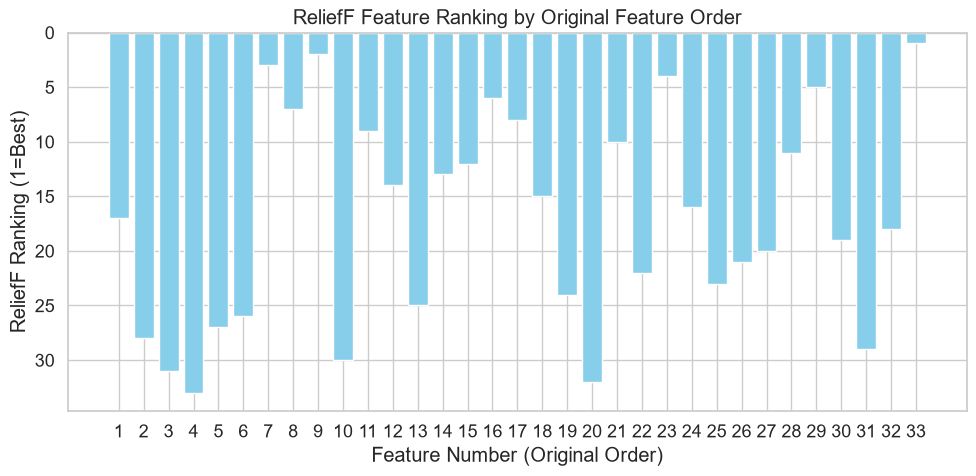

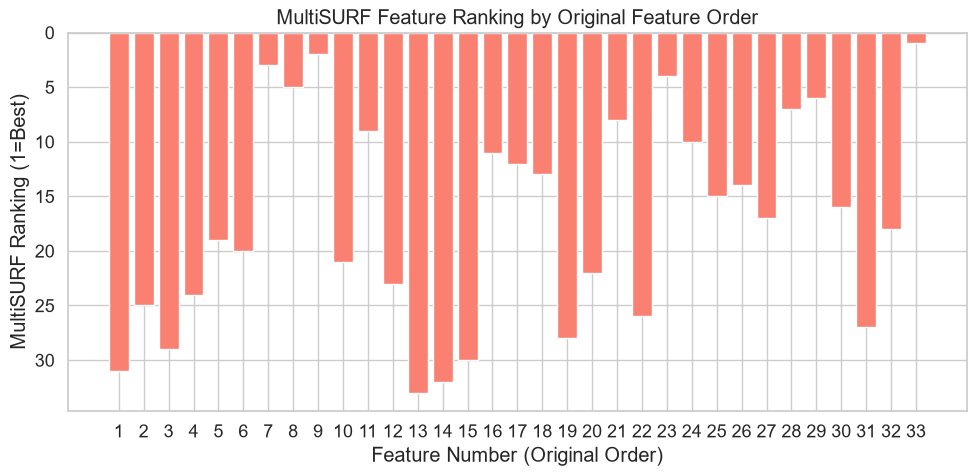

In [17]:
# Visualization: Feature Ranking (Y=Ranking, X=Feature Number, Original Order)
import matplotlib.pyplot as plt
import numpy as np

# Get feature names in original order
feature_numbers = np.arange(1, len(feature_names)+1)

# ReliefF: get ranking for each feature in original order
relieff_ranking = [
    [feat for feat, _ in relieff_sorted].index(f) + 1 for f in feature_names
]
plt.figure(figsize=(10, 5))
plt.bar(feature_numbers, relieff_ranking, color='skyblue')
plt.ylabel('ReliefF Ranking (1=Best)')
plt.xlabel('Feature Number (Original Order)')
plt.title('ReliefF Feature Ranking by Original Feature Order')
plt.xticks(feature_numbers)
plt.gca().invert_yaxis()  # 1 is best, so invert
plt.tight_layout()
plt.show()

# MultiSURF: get ranking for each feature in original order
multisurf_ranking = [
    [feat for feat, _ in multisurf_sorted].index(f) + 1 for f in feature_names
]
plt.figure(figsize=(10, 5))
plt.bar(feature_numbers, multisurf_ranking, color='salmon')
plt.ylabel('MultiSURF Ranking (1=Best)')
plt.xlabel('Feature Number (Original Order)')
plt.title('MultiSURF Feature Ranking by Original Feature Order')
plt.xticks(feature_numbers)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


## Model Development and Cross-Validation

In [18]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

print("="*60)
print("F1-OPTIMISED MODEL TUNING AND VOTING EVALUATION - Saudi")
print("="*60)

scoring_metric = "f1"
cv_splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

rf_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
}
xgb_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.1, 0.3],
    "subsample": [0.8, 1.0],
}
svm_param_grid = {
    "C": [0.1, 1, 10],
    "kernel": ["rbf"],
    "gamma": ["scale", "auto"],
}
dt_param_grid = {
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
}
gb_param_grid = {
    "n_estimators": [100, 200],
    "learning_rate": [0.05, 0.1],
    "max_depth": [3, 5],
    "subsample": [0.8, 1.0],
}

def prefix_grid(grid, prefix="clf"):
    return {f"{prefix}__{k}": v for k, v in grid.items()}

def build_model_pipeline(estimator, use_smote=True, smote_seed=None):
    steps = [
        ("target_encode", MEstimateTargetEncoder(columns=nominal_cols, m=m_value)),
        ("scale_non_binary", NonBinaryStandardScaler(binary_columns=binary_cols)),
    ]
    if use_smote:
        steps.append(("smote", SMOTE(random_state=SEED if smote_seed is None else smote_seed)))
    steps.append(("clf", estimator))
    return ImbPipeline(steps)

def tune_model(estimator, grid):
    pipeline = build_model_pipeline(estimator)
    search = GridSearchCV(
        pipeline,
        prefix_grid(grid),
        cv=cv_splitter,
        scoring=scoring_metric,
        n_jobs=-1,
        refit=True,
    )
    search.fit(X_train_raw_model, y_train)
    print(f"{estimator.__class__.__name__} best CV F1: {search.best_score_:.4f}")
    print(f"  best parameters: {search.best_params_}")
    return search

gs_rf = tune_model(RandomForestClassifier(random_state=SEED), rf_param_grid)
gs_xgb = tune_model(XGBClassifier(random_state=SEED, eval_metric="logloss"), xgb_param_grid)
gs_svm = tune_model(SVC(probability=True, random_state=SEED), svm_param_grid)
gs_dt = tune_model(DecisionTreeClassifier(random_state=SEED), dt_param_grid)
gs_gb = tune_model(GradientBoostingClassifier(random_state=SEED), gb_param_grid)

# Use the tuned classifier settings as the voting components. Preprocessing and
# SMOTE are applied by build_model_pipeline inside each CV fold.
rf = clone(gs_rf.best_estimator_.named_steps["clf"])
xgb = clone(gs_xgb.best_estimator_.named_steps["clf"])
svm = clone(gs_svm.best_estimator_.named_steps["clf"])
dt = clone(gs_dt.best_estimator_.named_steps["clf"])
gb = clone(gs_gb.best_estimator_.named_steps["clf"])

voting_clf = VotingClassifier(
    estimators=[("rf", clone(rf)), ("gb", clone(gb)), ("svm", clone(svm)), ("dt", clone(dt))],
    voting="soft",
)

# Every voting combination is evaluated and optimized independently. The
# additional combinations are shown in tables but are not added to the main
# top-N figure.
voting_models = {
    "General Voting": voting_clf,
    "Hard GB + XGBoost + SVM": VotingClassifier(
        estimators=[("gb", clone(gb)), ("xgb", clone(xgb)), ("svm", clone(svm))], voting="hard"
    ),
    "Hard RF + GB + XGBoost": VotingClassifier(
        estimators=[("rf", clone(rf)), ("gb", clone(gb)), ("xgb", clone(xgb))], voting="hard"
    ),
    "Hard RF + XGBoost + SVM": VotingClassifier(
        estimators=[("rf", clone(rf)), ("xgb", clone(xgb)), ("svm", clone(svm))], voting="hard"
    ),
    "Hard All Five": VotingClassifier(
        estimators=[("rf", clone(rf)), ("gb", clone(gb)), ("xgb", clone(xgb)), ("svm", clone(svm)), ("dt", clone(dt))], voting="hard"
    ),
    "Voting GB + XGBoost (equal weights)": VotingClassifier(
        estimators=[("gb", clone(gb)), ("xgb", clone(xgb))],
        voting="soft",
    ),
    "Voting RF + XGBoost": VotingClassifier(
        estimators=[("rf", clone(rf)), ("xgb", clone(xgb))],
        voting="soft",
    ),
    "Voting GB + SVM": VotingClassifier(
        estimators=[("gb", clone(gb)), ("svm", clone(svm))],
        voting="soft",
    ),
    "Voting GB + XGBoost + SVM": VotingClassifier(
        estimators=[("gb", clone(gb)), ("xgb", clone(xgb)), ("svm", clone(svm))],
        voting="soft",
    ),
    "Voting RF + GB + XGBoost": VotingClassifier(
        estimators=[("rf", clone(rf)), ("gb", clone(gb)), ("xgb", clone(xgb))],
        voting="soft",
    ),
    "Voting All Five": VotingClassifier(
        estimators=[("rf", clone(rf)), ("gb", clone(gb)), ("xgb", clone(xgb)), ("svm", clone(svm)), ("dt", clone(dt))],
        voting="soft",
    ),
}

cv_models = {
    "Random Forest": rf,
    "XGBoost": xgb,
    "SVM": svm,
    "Decision Tree": dt,
    "Gradient Boosting": gb,
}
cv_models.update(voting_models)

cv_results = []
for name, estimator in cv_models.items():
    scores = cross_val_score(
        build_model_pipeline(clone(estimator)),
        X_train_raw_model,
        y_train,
        cv=cv_splitter,
        scoring="f1",
        n_jobs=-1,
    )
    cv_results.append({"Model": name, "Mean CV F1": scores.mean(), "Std CV F1": scores.std()})
    print(f"{name}: mean CV F1={scores.mean():.4f}, std={scores.std():.4f}")

cv_results = pd.DataFrame(cv_results)
display(cv_results.sort_values("Mean CV F1", ascending=False).round(4))

def positive_scores(fitted_model, X):

    """Return probability, decision score, or hard positive-vote fraction."""
    classifier = fitted_model.named_steps["clf"]
    if isinstance(classifier, VotingClassifier) and classifier.voting == "hard":
        prepared = fitted_model.named_steps["target_encode"].transform(X)
        prepared = fitted_model.named_steps["scale_non_binary"].transform(prepared)
        return classifier.transform(prepared).mean(axis=1)
    try:
        return fitted_model.predict_proba(X)[:, 1]
    except (AttributeError, NotImplementedError):
        if hasattr(fitted_model, "decision_function"):
            return fitted_model.decision_function(X)
        return None

def run_to_run_variance(estimator, X_features, y_target, model_name, seeds=(SEED, SEED + 1, SEED + 2)):
    """Evaluate CV-F1 stability across seeds for a fixed feature subset."""
    rows = []
    for run_seed in seeds:
        run_estimator = clone(estimator)
        seed_params = {
            name: run_seed
            for name in run_estimator.get_params(deep=True)
            if name.endswith("random_state")
        }
        if seed_params:
            run_estimator.set_params(**seed_params)
        run_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=run_seed)
        run_scores = cross_val_score(
            build_model_pipeline(run_estimator, smote_seed=run_seed),
            X_features,
            y_target,
            cv=run_cv,
            scoring="f1",
            n_jobs=-1,
        )
        rows.append({"Model": model_name, "Seed": run_seed, "Mean CV F1": run_scores.mean(), "Fold SD": run_scores.std()})
    return pd.DataFrame(rows)


F1-OPTIMISED MODEL TUNING AND VOTING EVALUATION - Saudi
RandomForestClassifier best CV F1: 0.7628
  best parameters: {'clf__max_depth': None, 'clf__min_samples_leaf': 1, 'clf__min_samples_split': 2, 'clf__n_estimators': 200}
XGBClassifier best CV F1: 0.7873
  best parameters: {'clf__learning_rate': 0.1, 'clf__max_depth': 3, 'clf__n_estimators': 200, 'clf__subsample': 0.8}
SVC best CV F1: 0.7667
  best parameters: {'clf__C': 1, 'clf__gamma': 'scale', 'clf__kernel': 'rbf'}
DecisionTreeClassifier best CV F1: 0.6970
  best parameters: {'clf__max_depth': 10, 'clf__min_samples_leaf': 2, 'clf__min_samples_split': 5}
GradientBoostingClassifier best CV F1: 0.7911
  best parameters: {'clf__learning_rate': 0.1, 'clf__max_depth': 3, 'clf__n_estimators': 100, 'clf__subsample': 0.8}
Random Forest: mean CV F1=0.7628, std=0.0289
XGBoost: mean CV F1=0.7873, std=0.0219
SVM: mean CV F1=0.7667, std=0.0238
Decision Tree: mean CV F1=0.6970, std=0.0377
Gradient Boosting: mean CV F1=0.7911, std=0.0079
General

,Model,Mean CV F1,Std CV F1
7,Hard RF + GB + XGBoost,0.7938,0.0145
6,Hard GB + XGBoost + SVM,0.7928,0.0127
4,Gradient Boosting,0.7911,0.0079
13,Voting GB + XGBoost + SVM,0.7904,0.0185
12,Voting GB + SVM,0.7897,0.0267
14,Voting RF + GB + XGBoost,0.7893,0.0156
11,Voting RF + XGBoost,0.7882,0.0147
10,Voting GB + XGBoost (equal weights),0.7882,0.0112
1,XGBoost,0.7873,0.0219
9,Hard All Five,0.7868,0.0176


In [19]:
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from sklearn.base import clone
from sklearn.metrics import f1_score

print("="*60)
print("FOLD-LOCAL TOP-N FEATURE CURVES USING F1 - Saudi")
print("="*60)

max_n = len(feature_names)
cv_folds = cv_splitter
scoring = "f1"

base_model_templates = {
    "Random Forest": rf,
    "XGBoost": xgb,
    "SVM": svm,
    "Decision Tree": dt,
    "Gradient Boosting": gb,
}
model_templates = {**base_model_templates, **voting_models}


def make_selector(selector_name, feature_count, categorical_indices):
    common = {
        "n_features_to_select": feature_count,
        "categorical_features": categorical_indices,
        "n_jobs": 1,
    }
    if selector_name == "ReliefF":
        return ReliefF(n_neighbors=100, **common)
    return MultiSURF(**common)


def prepare_fold_rankings():
    cache = []
    for fold_number, (fit_positions, validation_positions) in enumerate(
        cv_folds.split(X_train_raw_model, y_train), start=1
    ):
        X_fit = X_train_raw_model.iloc[fit_positions].copy()
        y_fit = y_train.iloc[fit_positions]

        fold_encoder = MEstimateTargetEncoder(columns=nominal_cols, m=m_value)
        X_fit_encoded = fold_encoder.fit_transform(X_fit, y_fit)
        fold_scaler = NonBinaryStandardScaler(binary_columns=binary_cols)
        X_fit_prepared = fold_scaler.fit_transform(X_fit_encoded)

        fold_features = list(X_fit.columns)
        categorical_indices = [
            fold_features.index(column)
            for column in binary_cols
            if column in fold_features
        ]
        fold_rankings = {}
        for selector_name in ("ReliefF", "MultiSURF"):
            selector = make_selector(selector_name, len(fold_features), categorical_indices)
            selector.fit(np.asarray(X_fit_prepared, dtype=float), np.asarray(y_fit))
            order = np.argsort(selector.feature_importances_)[::-1]
            fold_rankings[selector_name] = [fold_features[index] for index in order]

        cache.append({
            "fold": fold_number,
            "fit_positions": fit_positions,
            "validation_positions": validation_positions,
            "rankings": fold_rankings,
        })
        print(f"Prepared fold-local ReliefF and MultiSURF rankings for fold {fold_number}/5")
    return cache


fold_local_ranking_cache = prepare_fold_rankings()


def score_one_fold(estimator, selected_features, fit_positions, validation_positions):
    fitted = build_model_pipeline(clone(estimator))
    fitted.fit(
        X_train_raw_model.iloc[fit_positions].loc[:, selected_features],
        y_train.iloc[fit_positions],
    )
    predictions = fitted.predict(
        X_train_raw_model.iloc[validation_positions].loc[:, selected_features]
    )
    return f1_score(y_train.iloc[validation_positions], predictions, zero_division=0)


def evaluate_top_n(selector_name, n, estimator):
    fold_scores = Parallel(n_jobs=-1)(
        delayed(score_one_fold)(
            estimator,
            fold["rankings"][selector_name][:n],
            fold["fit_positions"],
            fold["validation_positions"],
        )
        for fold in fold_local_ranking_cache
    )
    return float(np.mean(fold_scores))


scores = {
    "relief": {name: [] for name in model_templates},
    "multi": {name: [] for name in model_templates},
}

for n in range(1, max_n + 1):
    print(f"Evaluating feature count {n}/{max_n}")
    for name, estimator in model_templates.items():
        scores["relief"][name].append(evaluate_top_n("ReliefF", n, estimator))
        scores["multi"][name].append(evaluate_top_n("MultiSURF", n, estimator))

# Compatibility aliases used by the reporting and plotting cells.
rf_acc_relief = scores["relief"]["Random Forest"]
xgb_acc_relief = scores["relief"]["XGBoost"]
svm_acc_relief = scores["relief"]["SVM"]
dt_acc_relief = scores["relief"]["Decision Tree"]
gb_acc_relief = scores["relief"]["Gradient Boosting"]
voting_clf_acc_relief = scores["relief"]["General Voting"]
rf_acc_multi = scores["multi"]["Random Forest"]
xgb_acc_multi = scores["multi"]["XGBoost"]
svm_acc_multi = scores["multi"]["SVM"]
dt_acc_multi = scores["multi"]["Decision Tree"]
gb_acc_multi = scores["multi"]["Gradient Boosting"]
voting_clf_acc_multi = scores["multi"]["General Voting"]


def first_argmax(values):
    maximum = max(values)
    return next(i + 1 for i, value in enumerate(values) if value == maximum)


best_feature_counts = {
    selector_name: {
        model_name: first_argmax(model_scores)
        for model_name, model_scores in selector_scores.items()
    }
    for selector_name, selector_scores in [
        ("ReliefF", scores["relief"]),
        ("MultiSURF", scores["multi"]),
    ]
}

best_cv_f1 = {
    selector_name: {
        model_name: max(model_scores)
        for model_name, model_scores in selector_scores.items()
    }
    for selector_name, selector_scores in [
        ("ReliefF", scores["relief"]),
        ("MultiSURF", scores["multi"]),
    ]
}

best_rf_relief = best_feature_counts["ReliefF"]["Random Forest"]
best_xgb_relief = best_feature_counts["ReliefF"]["XGBoost"]
best_svm_relief = best_feature_counts["ReliefF"]["SVM"]
best_dt_relief = best_feature_counts["ReliefF"]["Decision Tree"]
best_gb_relief = best_feature_counts["ReliefF"]["Gradient Boosting"]
best_voting_relief = best_feature_counts["ReliefF"]["General Voting"]
best_rf_multi = best_feature_counts["MultiSURF"]["Random Forest"]
best_xgb_multi = best_feature_counts["MultiSURF"]["XGBoost"]
best_svm_multi = best_feature_counts["MultiSURF"]["SVM"]
best_dt_multi = best_feature_counts["MultiSURF"]["Decision Tree"]
best_gb_multi = best_feature_counts["MultiSURF"]["Gradient Boosting"]
best_voting_multi = best_feature_counts["MultiSURF"]["General Voting"]

voting_feature_rows = []
for selector_name, score_key in (("ReliefF", "relief"), ("MultiSURF", "multi")):
    for model_name in voting_models:
        n = best_feature_counts[selector_name][model_name]
        voting_feature_rows.append({
            "Feature Selection": selector_name,
            "Model": model_name,
            "Optimal Features": n,
            "Best CV F1": best_cv_f1[selector_name][model_name],
        })
voting_feature_summary = pd.DataFrame(voting_feature_rows)
print("Each classifier uses its own feature count selected with fold-local ranking:")
display(voting_feature_summary.sort_values(
    ["Feature Selection", "Best CV F1"], ascending=[True, False]
).round(4))
print("Feature-count rule: choose the smallest N attaining the maximum mean CV F1.")


# Select before evaluating any holdout predictions. Original full-feature
# CV scores already exist from the model-development cell.
from pathlib import Path
import json

results_dir = Path("saudi_reviewed_v1_results")
results_dir.mkdir(exist_ok=True)
all_features_cv = cv_results.set_index("Model")["Mean CV F1"].to_dict()
selection_rows = [
    {"Feature Selection": "All features", "Model": name,
      "Features": X_train_raw_model.shape[1], "CV F1": all_features_cv[name]}
    for name in model_templates
]
for selector_name, score_key in (("ReliefF", "relief"), ("MultiSURF", "multi")):
    for name in model_templates:
        n = best_feature_counts[selector_name][name]
        selection_rows.append({
            "Feature Selection": selector_name, "Model": name,
            "Features": n, "CV F1": scores[score_key][name][n - 1],
        })
training_cv_candidates = pd.DataFrame(selection_rows).sort_values(
    ["CV F1", "Features", "Feature Selection", "Model"],
    ascending=[False, True, True, True], kind="stable",
).reset_index(drop=True)
selected_configuration = training_cv_candidates.iloc[0].copy()
selected_key = (selected_configuration["Feature Selection"], selected_configuration["Model"])
training_cv_candidates.to_csv(results_dir / "training_cv_candidates.csv", index=False)
curve_rows = [
    {"Feature Selection": selector, "Model": name, "Features": n, "CV F1": value}
    for selector, key in (("ReliefF", "relief"), ("MultiSURF", "multi"))
    for name, values in scores[key].items()
    for n, value in enumerate(values, 1)
]
pd.DataFrame(curve_rows).to_csv(results_dir / "feature_count_curves.csv", index=False)
selection_details = {
    "choice": selected_configuration.to_dict(),
    "rule": "Maximum unrounded mean training CV F1, then fewer features, selector/model alphabetical order",
    "seed": SEED, "folds": cv_splitter.n_splits,
    "final_parameters": {name: estimator.get_params(deep=True)
                         for name, estimator in base_model_templates.items()},
    "search_grids": {"RF": rf_param_grid, "XGBoost": xgb_param_grid,
                     "SVM": svm_param_grid, "DT": dt_param_grid, "GB": gb_param_grid},
    "training_indices": X_train_raw_model.index.tolist(),
    "test_indices": X_test_raw_model.index.tolist(),
}
(results_dir / "training_selection.json").write_text(
    json.dumps(selection_details, indent=2, default=str), encoding="utf-8")
print("Configuration selected by training CV:")
display(selected_configuration.to_frame("Selected configuration"))


FOLD-LOCAL TOP-N FEATURE CURVES USING F1 - Saudi
Prepared fold-local ReliefF and MultiSURF rankings for fold 1/5
Prepared fold-local ReliefF and MultiSURF rankings for fold 2/5
Prepared fold-local ReliefF and MultiSURF rankings for fold 3/5
Prepared fold-local ReliefF and MultiSURF rankings for fold 4/5
Prepared fold-local ReliefF and MultiSURF rankings for fold 5/5
Evaluating feature count 1/33
Evaluating feature count 2/33
Evaluating feature count 3/33
Evaluating feature count 4/33
Evaluating feature count 5/33
Evaluating feature count 6/33
Evaluating feature count 7/33
Evaluating feature count 8/33
Evaluating feature count 9/33
Evaluating feature count 10/33
Evaluating feature count 11/33
Evaluating feature count 12/33
Evaluating feature count 13/33
Evaluating feature count 14/33
Evaluating feature count 15/33
Evaluating feature count 16/33
Evaluating feature count 17/33
Evaluating feature count 18/33
Evaluating feature count 19/33
Evaluating feature count 20/33
Evaluating feature c

,Feature Selection,Model,Optimal Features,Best CV F1
17,MultiSURF,Voting RF + XGBoost,32,0.7976
13,MultiSURF,Hard RF + GB + XGBoost,32,0.7955
12,MultiSURF,Hard GB + XGBoost + SVM,33,0.7948
18,MultiSURF,Voting GB + SVM,29,0.7947
19,MultiSURF,Voting GB + XGBoost + SVM,25,0.7936
20,MultiSURF,Voting RF + GB + XGBoost,32,0.7936
16,MultiSURF,Voting GB + XGBoost (equal weights),32,0.7911
14,MultiSURF,Hard RF + XGBoost + SVM,32,0.7909
15,MultiSURF,Hard All Five,32,0.7882
21,MultiSURF,Voting All Five,26,0.7868


Feature-count rule: choose the smallest N attaining the maximum mean CV F1.
Configuration selected by training CV:


,Selected configuration
Feature Selection,ReliefF
Model,Voting GB + XGBoost + SVM
Features,32
CV F1,0.802042


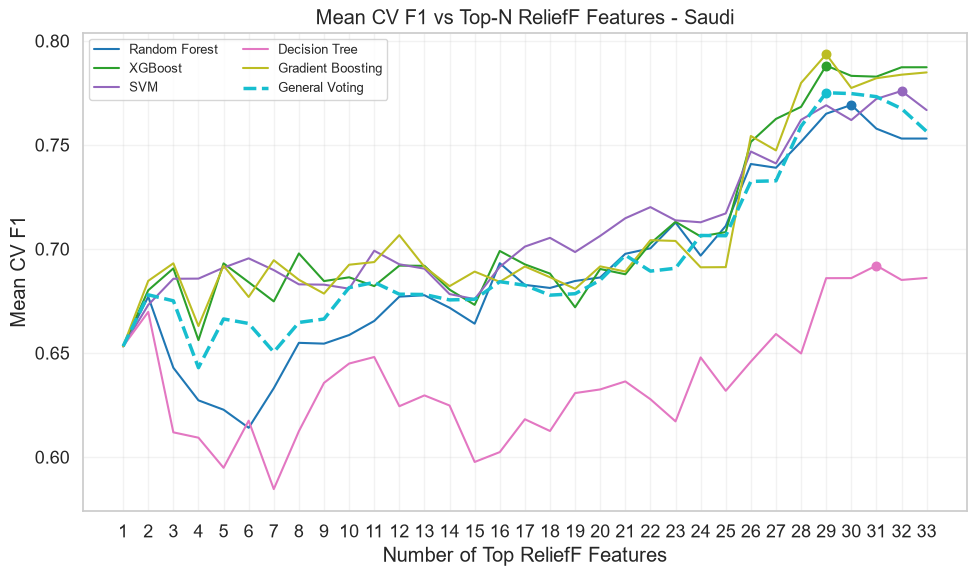

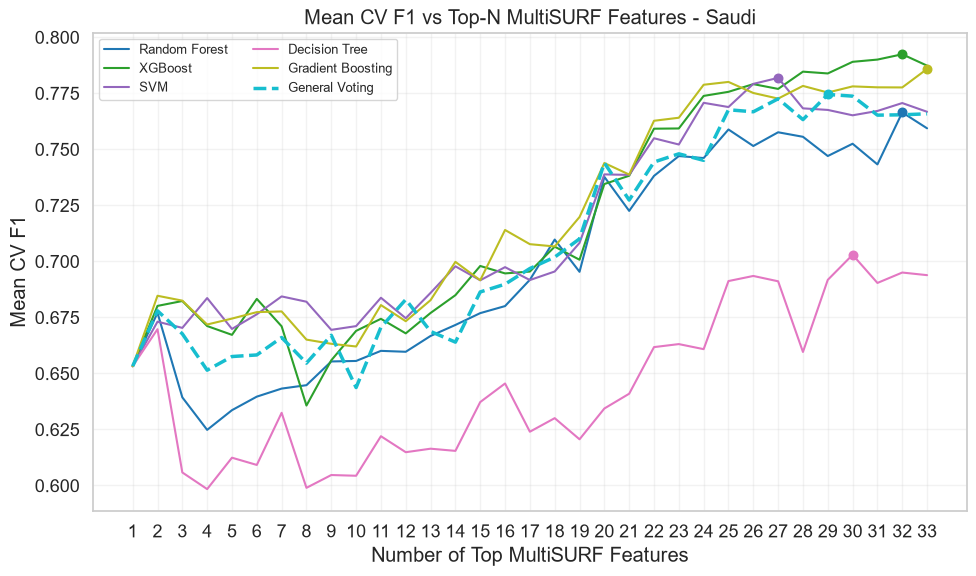

In [20]:
import numpy as np
import matplotlib.pyplot as plt

# Show the full Top-N behaviour for the five individual classifiers and the
# general soft-voting classifier. The next cell provides the focused
# ReliefF-versus-MultiSURF comparison for the final voting configuration.
n_values = np.arange(1, max_n + 1)
comparison_model_names = list(base_model_templates.keys()) + ["General Voting"]
missing_curve_models = [
    name for name in comparison_model_names
    if name not in scores["relief"] or name not in scores["multi"]
]
if missing_curve_models:
    raise KeyError(f"Missing Top-N CV curves for: {missing_curve_models}")


def plot_top_n_curves(score_key, selector_name):
    plt.figure(figsize=(10, 6))
    colours = plt.cm.tab10(np.linspace(0, 1, len(comparison_model_names)))
    for colour, model_name in zip(colours, comparison_model_names):
        curve = np.asarray(scores[score_key][model_name], dtype=float)
        optimal_n = best_feature_counts[selector_name][model_name]
        is_voting = model_name == "General Voting"
        plt.plot(
            n_values,
            curve,
            label=model_name,
            color=colour,
            linewidth=2.5 if is_voting else 1.5,
            linestyle="--" if is_voting else "-",
        )
        plt.scatter(optimal_n, curve[optimal_n - 1], color=colour, s=38, zorder=3)
    plt.xlabel(f"Number of Top {selector_name} Features")
    plt.ylabel("Mean CV F1")
    plt.title(f"Mean CV F1 vs Top-N {selector_name} Features - Saudi")
    plt.xticks(n_values)
    plt.legend(ncol=2, fontsize=9)
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()


plot_top_n_curves("relief", "ReliefF")
plot_top_n_curves("multi", "MultiSURF")


### Feature-count optimisation for the final voting configuration

This plot compares ReliefF and MultiSURF using the same final Saudi voting architecture. The selected point is the smallest feature count attaining the maximum mean five-fold CV F1.

## Holdout Evaluation

The CV-selected row is marked. Other holdout rows are descriptive comparisons on a split that was previously inspected. Average Precision (AP) summarises the precision-recall curve. Hard-voting AUC/AP use vote fractions.


In [21]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score

print("="*60)
print("FINAL HOLDOUT EVALUATION - Saudi")
print("="*60)

rankings = {"ReliefF": relieff_sorted, "MultiSURF": multisurf_sorted}
rankings["All features"] = [(column, None) for column in X_train_raw_model.columns]
best_feature_counts["All features"] = {name: X_train_raw_model.shape[1] for name in model_templates}
model_templates = {**base_model_templates, **voting_models}
model_sizes = {
    selector_name: {
        model_name: best_feature_counts[selector_name][model_name]
        for model_name in model_templates
    }
    for selector_name in rankings
}
cv_arrays = {
    "All features": {name: [all_features_cv[name]] * X_train_raw_model.shape[1] for name in model_templates},
    "ReliefF": scores["relief"],
    "MultiSURF": scores["multi"],
}

test_results = []
final_models = {}
for selector_name, ranking in rankings.items():
    for model_name, estimator in model_templates.items():
        n = model_sizes[selector_name][model_name]
        selected_features = [feature for feature, _ in ranking[:n]]
        model_pipeline = build_model_pipeline(clone(estimator))
        model_pipeline.fit(X_train_raw_model.loc[:, selected_features], y_train)
        X_eval = X_test_raw_model.loc[:, selected_features]
        y_pred = model_pipeline.predict(X_eval)
        y_score = positive_scores(model_pipeline, X_eval)
        test_results.append({
            "Feature Selection": selector_name,
            "Model": model_name,
            "Features": n,
            "CV F1": cv_arrays[selector_name][model_name][n - 1],
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision": precision_score(y_test, y_pred, zero_division=0),
            "Recall": recall_score(y_test, y_pred, zero_division=0),
            "F1": f1_score(y_test, y_pred, zero_division=0),
            "ROC AUC": roc_auc_score(y_test, y_score) if y_score is not None else np.nan,
            "Average Precision (AP)": average_precision_score(y_test, y_score) if y_score is not None else np.nan,
        })
        final_models[(selector_name, model_name)] = (model_pipeline, selected_features)


test_results = pd.DataFrame(test_results)
test_results["CV-selected"] = [
    (selector, name) == selected_key
    for selector, name in zip(test_results["Feature Selection"], test_results["Model"])
]
test_results.to_csv(results_dir / "holdout_metrics.csv", index=False)
selected_pipeline, selected_features = final_models[selected_key]
selected_predictions = selected_pipeline.predict(X_test_raw_model.loc[:, selected_features])
actual = y_test.to_numpy()
rng = np.random.default_rng(SEED)
bootstrap_f1 = []
for _ in range(2000):
    positions = rng.integers(0, len(actual), size=len(actual))
    bootstrap_f1.append(f1_score(
        actual[positions], selected_predictions[positions], zero_division=0))
f1_ci_low, f1_ci_high = np.quantile(bootstrap_f1, [0.025, 0.975])
selected_test_result = test_results.loc[test_results["CV-selected"]].iloc[0].copy()
selected_report = {**selected_test_result.to_dict(),
                   "F1 CI low": float(f1_ci_low), "F1 CI high": float(f1_ci_high),
                   "Bootstrap resamples": 2000, "Selected features": selected_features}
(results_dir / "selected_holdout_result.json").write_text(
    json.dumps(selected_report, indent=2, default=str), encoding="utf-8")
print("CV-selected configuration evaluated on the existing holdout:")
display(selected_test_result.to_frame("Selected model").round(4))
print(f"95% bootstrap F1 interval: {f1_ci_low:.3f} to {f1_ci_high:.3f}")
print("Conditional on this fitted model and split. This interval excludes model-selection uncertainty.")
print("For hard voting, ROC AUC and AP use the positive-vote fraction.")
display(test_results.sort_values(["Feature Selection", "F1"], ascending=[True, False]).round(4))

voting_results = test_results[test_results["Model"].isin(voting_models)].copy()
print("Voting classifier comparison (each model uses its own optimized feature count):")
display(voting_results.sort_values(["Feature Selection", "F1"], ascending=[True, False]).round(4))

variance_feature_counts = {
    selector_name: {
        model_name: best_feature_counts[selector_name][model_name]
        for model_name in voting_models
    }
    for selector_name in ("ReliefF", "MultiSURF")
}
optimized_variance_rows = []
for selector_name, ranking in rankings.items():
    if selector_name == "All features":
        continue
    for model_name, estimator in voting_models.items():
        n = variance_feature_counts[selector_name][model_name]
        selected_features = [feature for feature, _ in ranking[:n]]
        variance_frame = run_to_run_variance(
            estimator,
            X_train_raw_model.loc[:, selected_features],
            y_train,
            model_name,
        )
        variance_frame.insert(0, "Feature Selection", selector_name)
        variance_frame.insert(2, "Features", n)
        optimized_variance_rows.extend(variance_frame.to_dict("records"))
optimized_run_variance = pd.DataFrame(optimized_variance_rows)
print("Fixed-configuration stability for voting classifiers (not full selection uncertainty):")
display(optimized_run_variance.sort_values(["Feature Selection", "Model", "Seed"]).round(4))
run_variance_summary = (
    optimized_run_variance.groupby(["Feature Selection", "Model"])["Mean CV F1"]
    .agg(["mean", "std"])
    .rename(columns={"mean": "Run Mean CV F1", "std": "Run SD"})
)
display(run_variance_summary.round(4))

from sklearn.dummy import DummyClassifier
majority = DummyClassifier(strategy="most_frequent")
majority.fit(X_train_raw_model, y_train)
majority_pred = majority.predict(X_test_raw_model)
print("\nMajority-class baseline:")
print(f"  Accuracy={accuracy_score(y_test, majority_pred):.4f}, F1={f1_score(y_test, majority_pred, zero_division=0):.4f}, Recall={recall_score(y_test, majority_pred, zero_division=0):.4f}")


FINAL HOLDOUT EVALUATION - Saudi
CV-selected configuration evaluated on the existing holdout:


,Selected model
Feature Selection,ReliefF
Model,Voting GB + XGBoost + SVM
Features,32
CV F1,0.802042
Accuracy,0.820084
Precision,0.8
Recall,0.776699
F1,0.788177
ROC AUC,0.905054
Average Precision (AP),0.895484


95% bootstrap F1 interval: 0.724 to 0.847
Conditional on this fitted model and split. This interval excludes model-selection uncertainty.
For hard voting, ROC AUC and AP use the positive-vote fraction.


,Feature Selection,Model,Features,CV F1,Accuracy,Precision,Recall,F1,ROC AUC,Average Precision (AP),CV-selected
42,All features,Voting GB + XGBoost (equal weights),33,0.7882,0.8368,0.8333,0.7767,0.8040,0.9057,0.8970,False
46,All features,Voting RF + GB + XGBoost,33,0.7893,0.8368,0.8333,0.7767,0.8040,0.9037,0.8950,False
40,All features,Hard RF + XGBoost + SVM,33,0.7809,0.8326,0.8119,0.7961,0.8039,0.8447,0.7608,False
38,All features,Hard GB + XGBoost + SVM,33,0.7928,0.8326,0.8182,0.7864,0.8020,0.8559,0.7829,False
41,All features,Hard All Five,33,0.7868,0.8326,0.8182,0.7864,0.8020,0.8563,0.8100,False
36,All features,Gradient Boosting,33,0.7911,0.8326,0.8247,0.7767,0.8000,0.9020,0.8925,False
39,All features,Hard RF + GB + XGBoost,33,0.7938,0.8326,0.8316,0.7670,0.7980,0.8445,0.7677,False
33,All features,XGBoost,33,0.7873,0.8285,0.8229,0.7670,0.7940,0.9068,0.8992,False
43,All features,Voting RF + XGBoost,33,0.7882,0.8243,0.8211,0.7573,0.7879,0.9016,0.8934,False
45,All features,Voting GB + XGBoost + SVM,33,0.7904,0.8201,0.8061,0.7670,0.7861,0.9048,0.8923,False


Voting classifier comparison (each model uses its own optimized feature count):


,Feature Selection,Model,Features,CV F1,Accuracy,Precision,Recall,F1,ROC AUC,Average Precision (AP),CV-selected
42,All features,Voting GB + XGBoost (equal weights),33,0.7882,0.8368,0.8333,0.7767,0.8040,0.9057,0.8970,False
46,All features,Voting RF + GB + XGBoost,33,0.7893,0.8368,0.8333,0.7767,0.8040,0.9037,0.8950,False
40,All features,Hard RF + XGBoost + SVM,33,0.7809,0.8326,0.8119,0.7961,0.8039,0.8447,0.7608,False
38,All features,Hard GB + XGBoost + SVM,33,0.7928,0.8326,0.8182,0.7864,0.8020,0.8559,0.7829,False
41,All features,Hard All Five,33,0.7868,0.8326,0.8182,0.7864,0.8020,0.8563,0.8100,False
39,All features,Hard RF + GB + XGBoost,33,0.7938,0.8326,0.8316,0.7670,0.7980,0.8445,0.7677,False
43,All features,Voting RF + XGBoost,33,0.7882,0.8243,0.8211,0.7573,0.7879,0.9016,0.8934,False
45,All features,Voting GB + XGBoost + SVM,33,0.7904,0.8201,0.8061,0.7670,0.7861,0.9048,0.8923,False
44,All features,Voting GB + SVM,33,0.7897,0.8075,0.7822,0.7670,0.7745,0.8971,0.8822,False
47,All features,Voting All Five,33,0.7834,0.8075,0.7879,0.7573,0.7723,0.8913,0.8877,False


Fixed-configuration stability for voting classifiers (not full selection uncertainty):


,Feature Selection,Model,Features,Seed,Mean CV F1,Fold SD
33,MultiSURF,General Voting,29,42,0.7793,0.0231
34,MultiSURF,General Voting,29,43,0.7576,0.0274
35,MultiSURF,General Voting,29,44,0.7552,0.0280
45,MultiSURF,Hard All Five,32,42,0.7907,0.0149
46,MultiSURF,Hard All Five,32,43,0.7755,0.0202
...,...,...,...,...,...,...
28,ReliefF,Voting RF + GB + XGBoost,29,43,0.7858,0.0321
29,ReliefF,Voting RF + GB + XGBoost,29,44,0.7799,0.0160
18,ReliefF,Voting RF + XGBoost,29,42,0.7916,0.0117
19,ReliefF,Voting RF + XGBoost,29,43,0.7803,0.0274


Run Mean CV F1  Run SD
Feature Selection Model                                                      
MultiSURF         General Voting                               0.7640  0.0133
                  Hard All Five                                0.7775  0.0123
                  Hard GB + XGBoost + SVM                      0.7849  0.0081
                  Hard RF + GB + XGBoost                       0.7801  0.0122
                  Hard RF + XGBoost + SVM                      0.7781  0.0090
                  Voting All Five                              0.7698  0.0054
                  Voting GB + SVM                              0.7828  0.0152
                  Voting GB + XGBoost (equal weights)          0.7822  0.0129
                  Voting GB + XGBoost + SVM                    0.7854  0.0045
                  Voting RF + GB + XGBoost                     0.7858  0.0092
                  Voting RF + XGBoost                          0.7883  0.0101
ReliefF           General Voting                               0.7694  0.0082
                  Hard All Five                                0.7825  0.0082
                  Hard GB + XGBoost + SVM                      0.7899  0.0097
                  Hard RF + GB + XGBoost                       0.7838  0.0107
                  Hard RF + XGBoost + SVM                      0.7810  0.0062
                  Voting All Five                              0.7827  0.0103
                  Voting GB + SVM                              0.7967  0.0095
                  Voting GB + XGBoost (equal weights)          0.7877  0.0076
                  Voting GB + XGBoost + SVM                    0.7874  0.0093
                  Voting RF + GB + XGBoost                     0.7860  0.0062
                  Voting RF + XGBoost                          0.7830  0.0076


Majority-class baseline:
  Accuracy=0.5690, F1=0.0000, Recall=0.0000


### ReliefF versus MultiSURF using the CV-selected architecture


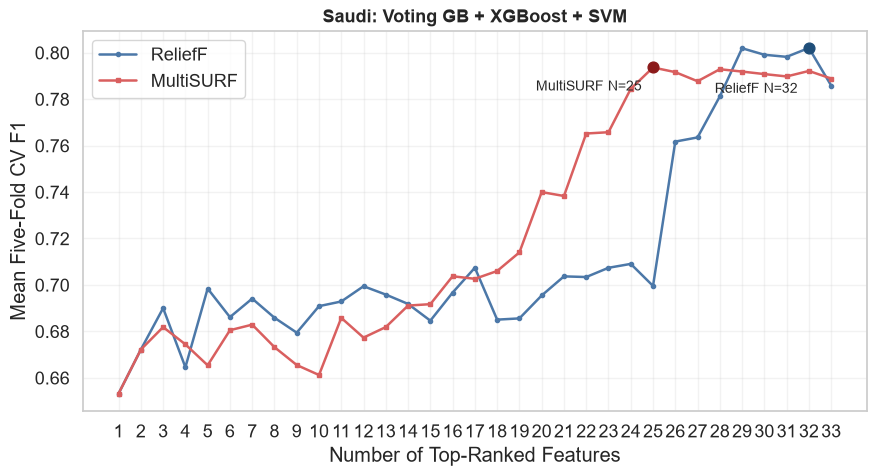

,Feature Selection,CV-Selected Architecture,Selected Features,Peak Mean CV F1
0,ReliefF,Voting GB + XGBoost + SVM,32,0.8020
1,MultiSURF,Voting GB + XGBoost + SVM,25,0.7936


CV-selected architecture used for both curves: Voting GB + XGBoost + SVM
Feature-count rule: choose the smallest N attaining the maximum mean CV F1.
Saved figure: saudi_reviewed_v1_cv_selected_feature_count.png
Saved curve data: saudi_reviewed_v1_cv_selected_feature_count.csv


In [22]:
# CV_SELECTED_SELECTOR_COMPARISON
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

required_objects = ["test_results", "scores", "best_feature_counts", "max_n"]
missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise RuntimeError(
        "Run the Top-N feature evaluation and final holdout evaluation first. "
        f"Missing objects: {missing_objects}"
    )


# Match the same architecture under both selectors, chosen by training CV.
winner_model_name = str(selected_configuration["Model"])

for score_key in ("relief", "multi"):
    if winner_model_name not in scores[score_key]:
        raise KeyError(f"Missing feature-count curve for {winner_model_name} in {score_key} scores")

n_values = np.arange(1, max_n + 1)
relief_curve = np.asarray(scores["relief"][winner_model_name], dtype=float)
multisurf_curve = np.asarray(scores["multi"][winner_model_name], dtype=float)
relief_n = best_feature_counts["ReliefF"][winner_model_name]
multisurf_n = best_feature_counts["MultiSURF"][winner_model_name]

curve_data = pd.DataFrame({
    "N Features": n_values,
    "ReliefF Mean CV F1": relief_curve,
    "MultiSURF Mean CV F1": multisurf_curve,
})

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(
    n_values, relief_curve, marker="o", markersize=3, linewidth=1.8,
    color="#4C78A8", label="ReliefF",
)
ax.plot(
    n_values, multisurf_curve, marker="s", markersize=3, linewidth=1.8,
    color="#D95F5F", label="MultiSURF",
)
ax.scatter(relief_n, relief_curve[relief_n - 1], color="#1F4E79", s=60, zorder=4)
ax.scatter(multisurf_n, multisurf_curve[multisurf_n - 1], color="#8B1A1A", s=60, zorder=4)
ax.annotate(
    f"ReliefF N={relief_n}",
    (relief_n, relief_curve[relief_n - 1]),
    xytext=(-8, -25), textcoords="offset points",
    ha="right", va="top", fontsize=10,
)
ax.annotate(
    f"MultiSURF N={multisurf_n}",
    (multisurf_n, multisurf_curve[multisurf_n - 1]),
    xytext=(-8, -9), textcoords="offset points",
    ha="right", va="top", fontsize=10,
)

model_label = winner_model_name.replace(" (equal weights)", "")

ax.set_xlabel("Number of Top-Ranked Features")
ax.set_ylabel("Mean Five-Fold CV F1")
ax.set_title("Saudi: " + model_label, fontsize=13, fontweight="bold")
ax.set_xticks(n_values)
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()

png_path = "saudi_reviewed_v1_cv_selected_feature_count.png"
csv_path = "saudi_reviewed_v1_cv_selected_feature_count.csv"
fig.savefig(png_path, dpi=300, bbox_inches="tight")
curve_data.to_csv(csv_path, index=False)
plt.show()

selected_points = pd.DataFrame({
    "Feature Selection": ["ReliefF", "MultiSURF"],
    "CV-Selected Architecture": [winner_model_name, winner_model_name],
    "Selected Features": [relief_n, multisurf_n],
    "Peak Mean CV F1": [
        relief_curve[relief_n - 1],
        multisurf_curve[multisurf_n - 1],
    ],
})
display(selected_points.round(4))
print(f"CV-selected architecture used for both curves: {winner_model_name}")
print("Feature-count rule: choose the smallest N attaining the maximum mean CV F1.")
print(f"Saved figure: {png_path}")
print(f"Saved curve data: {csv_path}")


## SHAP Analysis

SHAP model selected by training CV: ReliefF Voting GB + XGBoost + SVM


,Selected SHAP model
Feature Selection,ReliefF
Model,Voting GB + XGBoost + SVM
Features,32
CV F1,0.802042


100%|██████████| 100/100 [04:35<00:00,  2.76s/it]


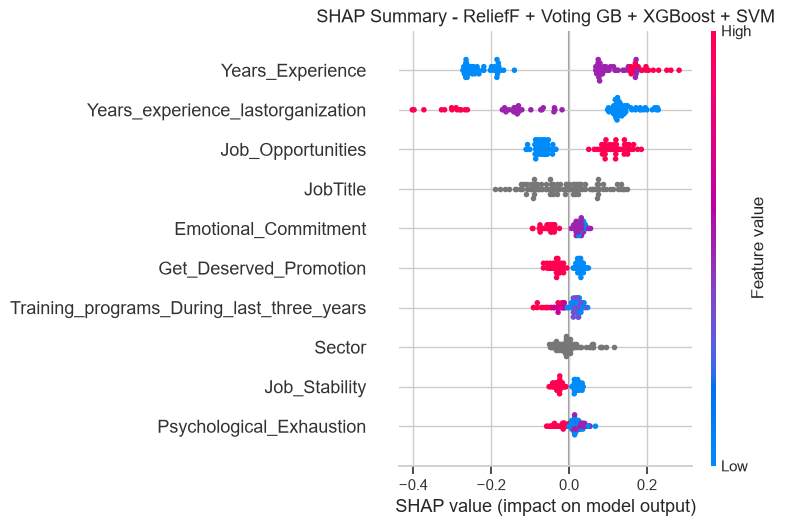

Dependence plots: ['Age', 'Years_Experience', 'Years_experience_lastorganization']


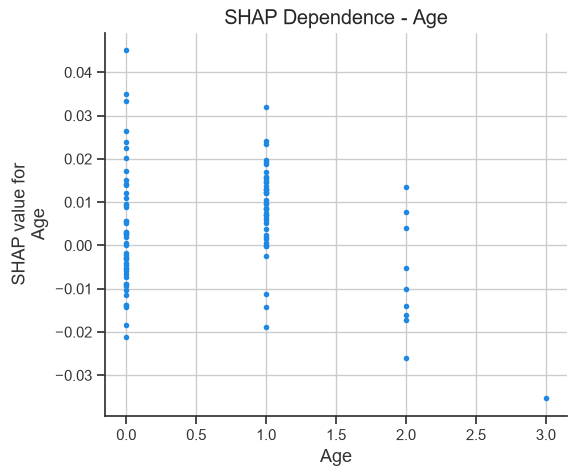

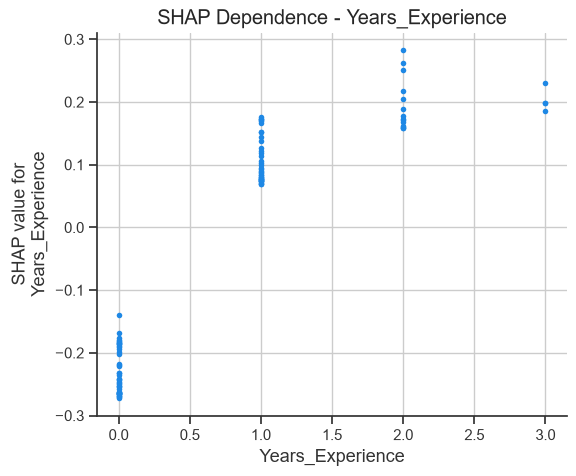

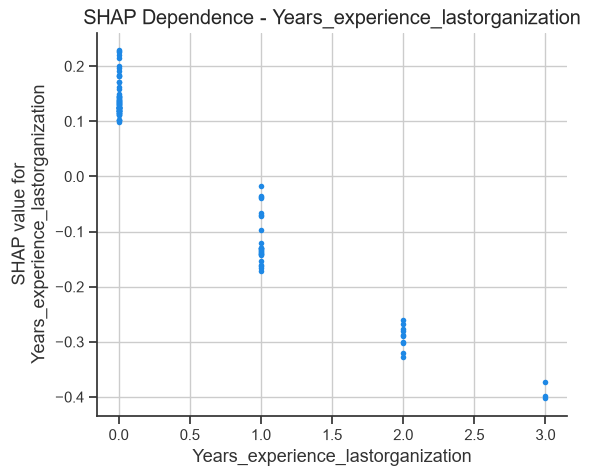

Local explanation: held-out row 919, actual=1, predicted=0, positive-class probability=0.3332, SHAP base (positive-class probability)=0.4577


,Feature,Value,SHAP value
0,Years_experience_lastorganization,0,0.1829
1,Years_Experience,1,0.1385
2,Training_programs_During_last_three_years,3,-0.0903
3,JobTitle,receptionist,-0.0824
4,Job_Opportunities,0,-0.0704
5,Get_Deserved_Promotion,1,-0.0504
6,Job_Stability,1,-0.0458
7,Rewards_Wages_Satisfaction,1,-0.0309
8,Allowances,1,0.0278
9,Emotional_Commitment,1,0.0256


,Feature,SMOTE endpoint effect,No-SMOTE endpoint effect,Direction agrees
0,Age,-0.0245,-0.0089,True
1,Years_Experience,0.4437,0.4515,True
2,Years_experience_lastorganization,-0.2404,-0.2427,True


Endpoint effects are sensitivity checks, not causal or cultural effects.


In [23]:
import os
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt
from sklearn.base import clone


if "selected_configuration" not in globals() or "final_models" not in globals():
    raise RuntimeError("Run the training CV selection and holdout evaluation first.")
shap_selector_name, shap_model_name = selected_key
shap_key = selected_key
fitted_classifier = final_models[shap_key][0].named_steps["clf"]
shap_value_scale = (
    "positive vote fraction" if isinstance(fitted_classifier, VotingClassifier)
    and fitted_classifier.voting == "hard" else "positive-class probability"
)
print("SHAP model selected by training CV:", shap_selector_name, shap_model_name)
display(selected_configuration.to_frame("Selected SHAP model"))

final_pipeline, shap_features = final_models[shap_key]
assert len(shap_features) == best_feature_counts[shap_selector_name][shap_model_name]

shap_smoke = os.environ.get("ATTRITION_SHAP_SMOKE", "0") == "1"
background_size = 10 if shap_smoke else 50
explanation_size = 4 if shap_smoke else 100
coalition_budget = 32 if shap_smoke else 500
background = X_train_raw_model.loc[:, shap_features].sample(
    n=min(background_size, len(X_train_raw_model)), random_state=SEED
)
X_shap_test = X_test_raw_model.loc[:, shap_features].iloc[:explanation_size].copy()

def shap_predict(values):
    frame = values if isinstance(values, pd.DataFrame) else pd.DataFrame(values, columns=shap_features)
    return positive_scores(final_pipeline, frame.loc[:, shap_features])

np.random.seed(SEED)
explainer = shap.KernelExplainer(shap_predict, background)
shap_values = explainer.shap_values(X_shap_test, nsamples=coalition_budget, l1_reg=0.0)
if isinstance(shap_values, list):
    shap_values = shap_values[-1]
shap_values = np.asarray(shap_values)
if shap_values.ndim == 3:
    shap_values = shap_values[:, :, -1]
local_base_value = float(np.asarray(explainer.expected_value).reshape(-1)[-1])

# Global importance summary for the selected final model.
shap.summary_plot(
    shap_values,
    X_shap_test,
    feature_names=shap_features,
    max_display=10,
    show=False,
)
shap_display_name = shap_model_name.replace(" (equal weights)", "")
plt.title(f"SHAP Summary - {shap_selector_name} + {shap_display_name}", fontsize=13)
plt.tight_layout()
plt.savefig(results_dir / "shap_summary.png", dpi=300, bbox_inches="tight")
plt.show()

mean_abs_shap = pd.Series(np.abs(shap_values).mean(axis=0), index=shap_features).sort_values(ascending=False)
seniority_candidates = ['Age', 'Years_Experience', 'Years_experience_lastorganization']
dependence_features = [f for f in seniority_candidates if f in shap_features]
dependence_features += [f for f in mean_abs_shap.index if f not in dependence_features]
dependence_features = dependence_features[:3]
print("Dependence plots:", dependence_features)
for feature in dependence_features:
    shap.dependence_plot(
        feature,
        shap_values,
        X_shap_test,
        feature_names=shap_features,
        interaction_index=None,
        show=False,
    )
    plt.title(f"SHAP Dependence - {feature}")
    plt.tight_layout()
    plt.show()

# A fixed local case is used instead of selecting a favourable observation.
local_index = 0
local_row_label = X_shap_test.index[local_index]
local_feature_order = np.argsort(np.abs(shap_values[local_index]))[::-1][:10]
local_prediction = positive_scores(final_pipeline, X_shap_test.iloc[[local_index]])[0]
local_class = int(final_pipeline.predict(X_shap_test.iloc[[local_index]])[0])
local_actual = int(y_test.loc[local_row_label])
local_explanation = pd.DataFrame({
    "Feature": [shap_features[i] for i in local_feature_order],
    "Value": [X_shap_test.iloc[local_index, i] for i in local_feature_order],
    "SHAP value": [shap_values[local_index, i] for i in local_feature_order],
})
print(
    f"Local explanation: held-out row {local_row_label}, actual={local_actual}, "
    f"predicted={local_class}, {shap_value_scale}={local_prediction:.4f}, "
    f"SHAP base ({shap_value_scale})={local_base_value:.4f}"
)
display(local_explanation.round(4))

# Sensitivity check: same selected estimator and features, changing SMOTE only.
seniority_features = [feature for feature in seniority_candidates if feature in shap_features]
if seniority_features:
    no_oversampling_pipeline = build_model_pipeline(clone(model_templates[shap_model_name]), use_smote=False)
    no_oversampling_pipeline.fit(X_train_raw_model.loc[:, shap_features], y_train)
    artifact_rows = []
    for feature in seniority_features:
        low_value, high_value = X_train_raw_model[feature].quantile([0.10, 0.90])
        low_frame = X_shap_test.copy()
        high_frame = X_shap_test.copy()
        low_frame[feature] = low_value
        high_frame[feature] = high_value
        oversampling_effect = np.mean(
            positive_scores(final_pipeline, high_frame)
            - positive_scores(final_pipeline, low_frame)
        )
        no_oversampling_effect = np.mean(
            positive_scores(no_oversampling_pipeline, high_frame)
            - positive_scores(no_oversampling_pipeline, low_frame)
        )
        artifact_rows.append({
            "Feature": feature,
            "SMOTE endpoint effect": oversampling_effect,
            "No-SMOTE endpoint effect": no_oversampling_effect,
            "Direction agrees": np.sign(oversampling_effect) == np.sign(no_oversampling_effect),
        })
    seniority_check = pd.DataFrame(artifact_rows)
    display(seniority_check.round(4))
    print("Endpoint effects are sensitivity checks, not causal or cultural effects.")
else:
    print("No predefined seniority feature is present in this selected subset.")


## Final Model Summary

In [24]:

# Final model summary, selected exclusively by training CV.
print("FINAL MODEL SUMMARY")
display(selected_test_result.to_frame("CV-selected configuration").round(4))
print(f"Holdout F1 95% bootstrap interval: {f1_ci_low:.3f} to {f1_ci_high:.3f}")
print("Matched architecture comparisons:")
display(test_results.pivot(
    index="Model", columns="Feature Selection", values="F1"
).reindex(columns=["All features", "ReliefF", "MultiSURF"]).round(4))
print("Existing holdout comparisons are descriptive. Selection was fixed before holdout evaluation.")


FINAL MODEL SUMMARY


,CV-selected configuration
Feature Selection,ReliefF
Model,Voting GB + XGBoost + SVM
Features,32
CV F1,0.802042
Accuracy,0.820084
Precision,0.8
Recall,0.776699
F1,0.788177
ROC AUC,0.905054
Average Precision (AP),0.895484


Holdout F1 95% bootstrap interval: 0.724 to 0.847
Matched architecture comparisons:


Feature Selection,All features,ReliefF,MultiSURF
Model,,,
Decision Tree,0.6965,0.6939,0.7150
General Voting,0.7586,0.7662,0.7638
Gradient Boosting,0.8000,0.7879,0.7980
Hard All Five,0.8020,0.7879,0.7902
Hard GB + XGBoost + SVM,0.8020,0.8000,0.8020
Hard RF + GB + XGBoost,0.7980,0.7959,0.7921
Hard RF + XGBoost + SVM,0.8039,0.7941,0.7767
Random Forest,0.7310,0.7487,0.7136
SVM,0.7810,0.7476,0.7834


Existing holdout comparisons are descriptive. Selection was fixed before holdout evaluation.
